# ModernBERT-base Experiment Analysis

## 1. Introduction

ModernBERT-base is the pretrained encoder identified by `answerdotai/ModernBERT-base`. The saved implementation uses `ModernBertForSequenceClassification` and its matching tokenizer. It was included to investigate a modern pretrained encoder implementation for SUM answerability classification. The project uses FP32 SDPA attention and disables the optional reference compilation path; this analysis concerns that recorded configuration, not every acceleration mode.

This notebook analyzes binary **answerability classification**, not numerical problem solving. Labels are `ANSWERABLE = 0` and `UNANSWERABLE = 1`; UNANSWERABLE is the positive class for precision, recall and F1. SUM provides the fixed training, validation and internal test splits; UMWP and MATE provide external evaluation. Each model family is analyzed separately; cross-model synthesis belongs in the final project report.

Only saved JSON/CSV artifacts are read. No training, model loading, inference, downloads or dataset preparation occurs. Run **Run All** from the project root or `notebooks/` with pandas, matplotlib and Jupyter/IPython installed. Model checkpoints and GPU access are not required.

Sources: `NOTEBOOK_GUIDELINES.md`, `src/22_train_encoder.py::load_split`, `compute_metrics`, `main`, and `src/24_evaluate_encoders.py::load_dataset`, `resolve_selection`, `evaluate_dataset`. The historical snapshots in `PROJECT_CONTEXT.md` and `PROJECT_PROGRESS.md` predate these results; current saved artifacts govern this analysis.

In [1]:
MODEL_FAMILY = 'modernbert'
MODEL_NAME = 'ModernBERT-base'
MODEL_ID = 'answerdotai/ModernBERT-base'
RECORDED_SELECTED_RUN = 'run_06'
EXCLUDED_RUNS = set()

from pathlib import Path
import json
import math

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

PROJECT_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / 'src/22_train_encoder.py').is_file()
     and (p / 'results' / MODEL_FAMILY).is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Start from the CDS1092 project root or notebooks directory.')
RESULTS_DIR = PROJECT_ROOT / 'results' / MODEL_FAMILY
LABELS = ['ANSWERABLE', 'UNANSWERABLE']
METRICS = ['eval_accuracy', 'eval_precision', 'eval_recall', 'eval_f1']
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})


def read_json(path):
    with path.open(encoding="utf-8") as handle:
        return json.load(handle)

def load_run(directory):
    report = read_json(directory / "validation_metrics.json")
    history = pd.read_csv(directory / "training_history.csv")
    metadata = report["configuration"]
    config_path = directory / "config.json"
    if config_path.is_file():
        config = read_json(config_path)
        for key in config.keys() & metadata.keys():
            if config[key] != metadata[key]:
                raise ValueError(f"{directory.name}: conflicting configuration field {key}")
        config = {**metadata, **config}
        config_source = "config.json + validation_metrics.json"
    else:
        raise FileNotFoundError(config_path)

    # Trainer logs its training summary before evaluate() is called again.
    # Separate events by that boundary, not by epoch: the restored model's
    # evaluation inherits the last training epoch in Trainer state.
    required = {"epoch", "step", "loss", "eval_loss", *METRICS, "train_runtime"}
    if not required.issubset(history.columns):
        raise ValueError(f"{directory.name}: missing history columns {required - set(history)}")
    summaries = history.index[history["train_runtime"].notna()]
    if len(summaries) != 1:
        raise ValueError(f"{directory.name}: expected exactly one training-summary event")
    boundary = summaries[0]
    epoch_events = history.loc[history.index < boundary]
    validation = epoch_events.loc[epoch_events["eval_f1"].notna()].copy()
    training = epoch_events.loc[epoch_events["loss"].notna()].copy()
    restored = history.loc[(history.index > boundary) & history["eval_f1"].notna()]
    if validation.empty or training.empty or len(restored) != 1:
        raise ValueError(f"{directory.name}: unexpected training/evaluation event structure")
    if validation["epoch"].duplicated().any() or training["epoch"].duplicated().any():
        raise ValueError(f"{directory.name}: ambiguous repeated epoch events")
    for events, columns in [(training, ['loss', 'epoch', 'step']),
                            (validation, ['eval_loss', *METRICS, 'epoch', 'step'])]:
        if not events[columns].map(math.isfinite).all().all():
            raise ValueError(f'{directory.name}: non-finite recorded trajectory')
    checkpoint_step = int(report["best_checkpoint"].replace("\\", "/").rsplit("checkpoint-", 1)[1])
    candidates = validation.loc[validation["step"].eq(checkpoint_step)]
    if len(candidates) != 1:
        raise ValueError(f"{directory.name}: best checkpoint has no unique epoch event")
    best = candidates.iloc[0]
    checkpoint_f1 = report["best_checkpoint_validation_f1"]
    if not math.isclose(best["eval_f1"], checkpoint_f1, abs_tol=1e-12, rel_tol=0):
        raise ValueError(f"{directory.name}: checkpoint F1 and epoch event disagree")
    if not math.isclose(validation["eval_f1"].max(), checkpoint_f1, abs_tol=1e-12, rel_tol=0):
        raise ValueError(f"{directory.name}: recorded checkpoint is not a maximum-F1 event")
    for metric in ["eval_loss", *METRICS]:
        if not math.isclose(restored.iloc[0][metric], report["best_validation_metrics"][metric],
                            abs_tol=1e-12, rel_tol=0):
            raise ValueError(f"{directory.name}: restored evaluation and JSON disagree")
    return {"config": config, "config_source": config_source, "report": report,
            "training": training, "validation": validation, "best": best,
            "restored": restored.iloc[0], "checkpoint_f1": checkpoint_f1}

run_directories = sorted(p for p in RESULTS_DIR.glob('run_*') if p.is_dir())
expected_all = {f'run_{i:02d}' for i in range(1, 9)}
if {p.name for p in run_directories} != expected_all:
    raise ValueError(f'{MODEL_NAME}: expected run_01 through run_08; review notebook scope.')
completed_names = sorted(expected_all - EXCLUDED_RUNS)
runs = {name: load_run(RESULTS_DIR / name) for name in completed_names}
run_labels = {name: f"Run {int(name.split('_')[1]):02d}" for name in runs}
for name, run in runs.items():
    c = run['config']
    if c['model_name'] != MODEL_ID or c['label_to_id'] != {'ANSWERABLE': 0, 'UNANSWERABLE': 1}:
        raise ValueError(f'{name}: model identity or labels differ')
    if c['model_parameter_dtype'] != 'torch.float32' or c['fp16'] or c['bf16']:
        raise ValueError(f'{name}: expected the completed FP32 protocol')
print(f'Loaded {len(runs)} completed FP32 runs from {RESULTS_DIR.relative_to(PROJECT_ROOT)}.')

Loaded 8 completed FP32 runs from results\modernbert.


## 2. Experiment Configuration

The shared table loads each completed run's `config.json`, `validation_metrics.json.configuration` and `training_history.csv`. Overlapping fields must agree. Best epochs are matched to the saved checkpoint step in the original validation event, never inferred from the final reevaluation's epoch metadata.

Changing the maximum epoch budget also changes the planned linear learning-rate schedule and warmup. The scripts compute `ceil(ceil(train_examples / batch_size) * max_epochs * warmup_ratio)` warmup steps. All experiments initialize from the original pretrained model; longer-budget runs are not resumed shorter runs.

**Dataset provenance:** SUM is prepared from `lime-nlp/Synthetic_Unanswerable_Math` by `src/03_prepare_sum.py` (`SOURCE_URL`, `build_groups`, `assign_groups`, `expand`, `validate`). It uses the project's fixed grouped splits, rather than the publisher's separate test file. UMWP is prepared from `data/raw/umwp/StandardDataset.jsonl` by `src/08_prepare_umwp.py::main`. MATE preparation is documented in `13_mate_dataset_analysis.ipynb`. No dataset regeneration occurs in this analysis. The retained test datasets are balanced; original question text is preserved by preparation, while tokenization applies model-specific subword encoding and truncation.

In [2]:
configuration_rows = []
for name, run in runs.items():
    c = run['config']
    planned = math.ceil(c['train_examples'] / c['batch_size']) * c['max_epochs']
    if planned != c['planned_optimizer_steps'] or math.ceil(planned * c['warmup_ratio']) != c['warmup_steps']:
        raise ValueError(f'{name}: inconsistent planned steps or warmup')
    configuration_rows.append({
        'Run': run_labels[name], 'Learning rate': c['learning_rate'],
        'Maximum epochs': c['max_epochs'], 'Completed epochs': int(run['training']['epoch'].max()),
        'Best epoch': int(run['best']['epoch']), 'Planned optimizer steps': planned,
        'Warmup steps': c['warmup_steps']})
configuration_table = pd.DataFrame(configuration_rows).set_index('Run')
display(configuration_table.style.format({'Learning rate': '{:.0e}'}))
shared_keys = ['model_name', 'max_length', 'batch_size', 'eval_batch_size', 'weight_decay',
               'warmup_ratio', 'random_seed', 'data_seed', 'gradient_accumulation_steps',
               'optimizer', 'scheduler', 'early_stopping_patience', 'train_examples', 'validation_examples']
shared = {}
for key in shared_keys:
    values = [run['config'][key] for run in runs.values()]
    if any(value != values[0] for value in values):
        raise ValueError(f'Setting is not shared across runs: {key}')
    shared[key] = values[0]
if (shared['train_examples'], shared['validation_examples']) != (51072, 10944):
    raise ValueError('Unexpected SUM training/validation sizes')
display(Markdown(
    f"All completed runs use **{shared['model_name']}**, train/evaluation batch size "
    f"**{shared['batch_size']}/{shared['eval_batch_size']}**, maximum length "
    f"**{shared['max_length']} tokens**, weight decay **{shared['weight_decay']}**, "
    f"warmup ratio **{shared['warmup_ratio']}**, seed/data seed "
    f"**{shared['random_seed']}/{shared['data_seed']}**, gradient accumulation "
    f"**{shared['gradient_accumulation_steps']}**, **{shared['optimizer']}** and a "
    f"**{shared['scheduler']}** scheduler. Full encoder and classification-head parameters "
    "are fine-tuned in FP32; FP16 and BF16 are disabled. The scripts evaluate, save and log "
    "each epoch, retain at most two checkpoints, restore the best checkpoint, and use "
    f"early stopping patience **{shared['early_stopping_patience']}** with threshold 0. "
    "These last callback/save settings are explicit in the training scripts, rather than "
    "assumed library defaults."))
dataset_table = pd.DataFrame([
    {'Split': 'SUM train', 'Examples': shared['train_examples'], 'Purpose': 'Parameter updates',
     'Project path': 'data/processed/sum/train.csv'},
    {'Split': 'SUM validation', 'Examples': shared['validation_examples'], 'Purpose': 'Checkpoint and run selection',
     'Project path': 'data/processed/sum/validation.csv'},
    {'Split': 'SUM Test', 'Examples': 10944, 'Purpose': 'Frozen internal evaluation',
     'Project path': 'data/processed/sum/test.csv'},
    {'Split': 'UMWP', 'Examples': 5200, 'Purpose': 'Frozen external evaluation',
     'Project path': 'data/processed/umwp/test.csv'}]).set_index('Split')
display(dataset_table)
display(Markdown(
    "The training and validation counts are checked against saved metadata; test counts "
    "are checked against evaluation artifacts in Section 6. Only question text is model input. "
    "Training loaders validate text/labels; the fixed SUM preparation groups linked question "
    "pairs before splitting, and the shared trainer checks train/validation pair-ID and exact-text "
    "isolation. Tokenization truncates at the configured maximum length and pads dynamically "
    "per batch, without adding solutions or metadata as input. These notebooks read result "
    "artifacts only and do not reload, resplit or alter datasets."))
provenance = pd.DataFrame([
    {'Run': run_labels[name], 'Model class': r['config']['model_class'],
     'Tokenizer class': r['config']['tokenizer_class'],
     'Attention backend': r['config'].get('attention_implementation') or 'Not recorded',
     'Pretrained revision': r['config'].get('pretrained_revision_resolved') or 'Unavailable',
     'PyTorch': r['config']['software_versions']['torch'],
     'Transformers': r['config']['software_versions']['transformers']}
    for name, r in runs.items()]).set_index('Run')
display(provenance)
display(Markdown(
    "Runtime metadata is shown per run so missing backend/revision information is not "
    "silently borrowed from another run. The original absolute training paths are provenance, "
    "not a local dependency. Model loading uses the model-specific tokenizer and sequence "
    "classification architecture; vocabulary-ID and padding compatibility are checked by the scripts."))

,Learning rate,Maximum epochs,Completed epochs,Best epoch,Planned optimizer steps,Warmup steps
Run,,,,,,
Run 01,3e-05,5,5,5,7980,399
Run 02,3e-05,7,7,7,11172,559
Run 03,4e-05,5,5,5,7980,399
Run 04,4e-05,7,7,7,11172,559
Run 05,5e-05,5,5,4,7980,399
Run 06,5e-05,7,7,7,11172,559
Run 07,6e-05,7,7,7,11172,559
Run 08,5e-05,10,7,5,15960,798


All completed runs use **answerdotai/ModernBERT-base**, train/evaluation batch size **32/32**, maximum length **256 tokens**, weight decay **0.01**, warmup ratio **0.05**, seed/data seed **42/42**, gradient accumulation **1**, **adamw_torch** and a **linear** scheduler. Full encoder and classification-head parameters are fine-tuned in FP32; FP16 and BF16 are disabled. The scripts evaluate, save and log each epoch, retain at most two checkpoints, restore the best checkpoint, and use early stopping patience **2** with threshold 0. These last callback/save settings are explicit in the training scripts, rather than assumed library defaults.

,Examples,Purpose,Project path
Split,,,
SUM train,51072,Parameter updates,data/processed/sum/train.csv
SUM validation,10944,Checkpoint and run selection,data/processed/sum/validation.csv
SUM Test,10944,Frozen internal evaluation,data/processed/sum/test.csv
UMWP,5200,Frozen external evaluation,data/processed/umwp/test.csv


The training and validation counts are checked against saved metadata; test counts are checked against evaluation artifacts in Section 6. Only question text is model input. Training loaders validate text/labels; the fixed SUM preparation groups linked question pairs before splitting, and the shared trainer checks train/validation pair-ID and exact-text isolation. Tokenization truncates at the configured maximum length and pads dynamically per batch, without adding solutions or metadata as input. These notebooks read result artifacts only and do not reload, resplit or alter datasets.

,Model class,Tokenizer class,Attention backend,Pretrained revision,PyTorch,Transformers
Run,,,,,,
Run 01,ModernBertForSequenceClassification,TokenizersBackend,sdpa,Unavailable,2.11.0+cu128,5.22.2
Run 02,ModernBertForSequenceClassification,TokenizersBackend,sdpa,Unavailable,2.11.0+cu128,5.22.2
Run 03,ModernBertForSequenceClassification,TokenizersBackend,sdpa,Unavailable,2.11.0+cu128,5.22.2
Run 04,ModernBertForSequenceClassification,TokenizersBackend,sdpa,Unavailable,2.11.0+cu128,5.22.2
Run 05,ModernBertForSequenceClassification,TokenizersBackend,sdpa,Unavailable,2.11.0+cu128,5.22.2
Run 06,ModernBertForSequenceClassification,TokenizersBackend,sdpa,Unavailable,2.11.0+cu128,5.22.2
Run 07,ModernBertForSequenceClassification,TokenizersBackend,sdpa,Unavailable,2.11.0+cu128,5.22.2
Run 08,ModernBertForSequenceClassification,TokenizersBackend,sdpa,Unavailable,2.11.0+cu128,5.22.2


Runtime metadata is shown per run so missing backend/revision information is not silently borrowed from another run. The original absolute training paths are provenance, not a local dependency. Model loading uses the model-specific tokenizer and sequence classification architecture; vocabulary-ID and padding compatibility are checked by the scripts.

## 3. Validation Results

Each row contains the original validation metrics for that run's selected checkpoint. Predictions use argmax; binary precision, recall and F1 use `pos_label=1` and `zero_division=0`. Selection uses the saved **best-checkpoint validation F1**. The recorded selected row is bold; the ranking is checked using validation artifacts before test results are loaded.

,Best epoch,Accuracy,Precision (UNANSWERABLE),Recall (UNANSWERABLE),F1 (UNANSWERABLE)
Run,,,,,
Run 01,5,0.877741,0.893714,0.857456,0.875210
Run 02,7,0.875274,0.893466,0.852156,0.872323
Run 03,5,0.875822,0.887946,0.860197,0.873851
Run 04,7,0.880665,0.899808,0.856725,0.877738
Run 05,4,0.877193,0.884214,0.868056,0.876060
Run 06,7,0.882950,0.906814,0.853618,0.879413
Run 07,7,0.882310,0.904955,0.854349,0.878925
Run 08,5,0.875731,0.889394,0.858187,0.873512


All completed runs have matching original checkpoint and post-restoration F1. The final reevaluation remains a separate event, even when its values agree.

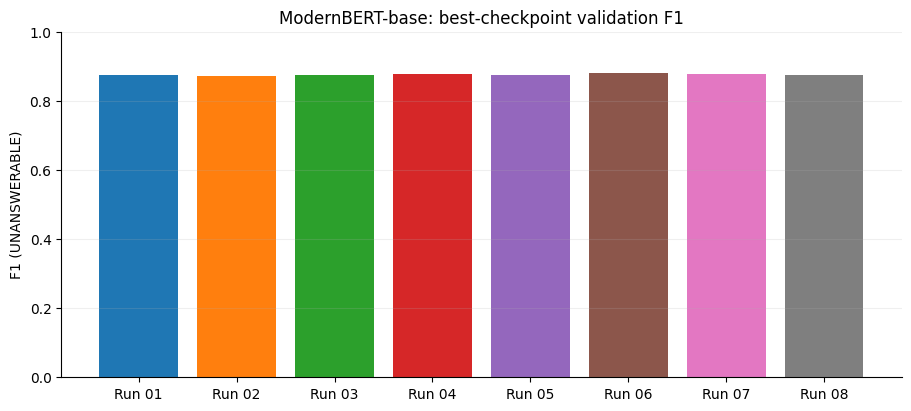

**Run 06** has the highest validation F1 (**0.879413**), ahead of Run 07 by **0.0488 percentage points**. All results use one recorded seed; this ranking does not establish statistical significance or a global optimum.

In [3]:
ranking = sorted(runs, key=lambda name: runs[name]['checkpoint_f1'], reverse=True)
selected_run = RECORDED_SELECTED_RUN
if ranking[0] != selected_run:
    raise ValueError('Validation ranking no longer confirms the recorded selected run.')
validation_table = pd.DataFrame([
    {'Run': run_labels[name], 'Best epoch': int(r['best']['epoch']),
     'Accuracy': r['best']['eval_accuracy'], 'Precision (UNANSWERABLE)': r['best']['eval_precision'],
     'Recall (UNANSWERABLE)': r['best']['eval_recall'], 'F1 (UNANSWERABLE)': r['checkpoint_f1']}
    for name, r in runs.items()]).set_index('Run')
display(validation_table.style.format({c: '{:.6f}' for c in validation_table.columns[1:]})
        .set_properties(subset=pd.IndexSlice[[run_labels[selected_run]], :], **{'font-weight': 'bold'}))
reevaluations = pd.DataFrame([
    {'Run': run_labels[name], 'Checkpoint epoch': int(r['best']['epoch']),
     'Checkpoint F1': r['checkpoint_f1'], 'Post-restoration F1': r['restored']['eval_f1'],
     'Difference': r['restored']['eval_f1'] - r['checkpoint_f1']}
    for name, r in runs.items()]).set_index('Run')
discrepancies = reevaluations.loc[reevaluations['Difference'].abs() > 1e-12]
if not discrepancies.empty:
    display(Markdown('**Recorded checkpoint / post-restoration discrepancies:**'))
    display(discrepancies.style.format(precision=9))
else:
    display(Markdown('All completed runs have matching original checkpoint and post-restoration F1. '
                     'The final reevaluation remains a separate event, even when its values agree.'))
fig, ax = plt.subplots(figsize=(9, 4), layout='constrained')
colors = {name: plt.get_cmap('tab10')(i) for i, name in enumerate(runs)}
positions = list(range(len(runs)))
ax.bar(positions, [r['checkpoint_f1'] for r in runs.values()], color=[colors[n] for n in runs])
ax.set_xticks(positions, [run_labels[n] for n in runs])
ax.set(title=f'{MODEL_NAME}: best-checkpoint validation F1', ylabel='F1 (UNANSWERABLE)', ylim=(0, 1))
ax.grid(axis='y', alpha=0.2)
plt.show()
runner_up = ranking[1]
margin_pp = 100 * (runs[selected_run]['checkpoint_f1'] - runs[runner_up]['checkpoint_f1'])
display(Markdown(
    f"**{run_labels[selected_run]}** has the highest validation F1 "
    f"(**{runs[selected_run]['checkpoint_f1']:.6f}**), ahead of {run_labels[runner_up]} "
    f"by **{margin_pp:.4f} percentage points**. All results use one recorded seed; "
    "this ranking does not establish statistical significance or a global optimum."))

## 4. Training Analysis

The three trajectories show epoch training loss, validation loss and UNANSWERABLE F1. All completed runs are included in two explicitly labeled cohorts with stable colors across figures. Actual epoch coordinates are preserved. The post-training restored-model evaluation is separated at the `train_runtime` summary boundary and excluded from curves; `groupby(epoch).last()` would incorrectly mix these events.

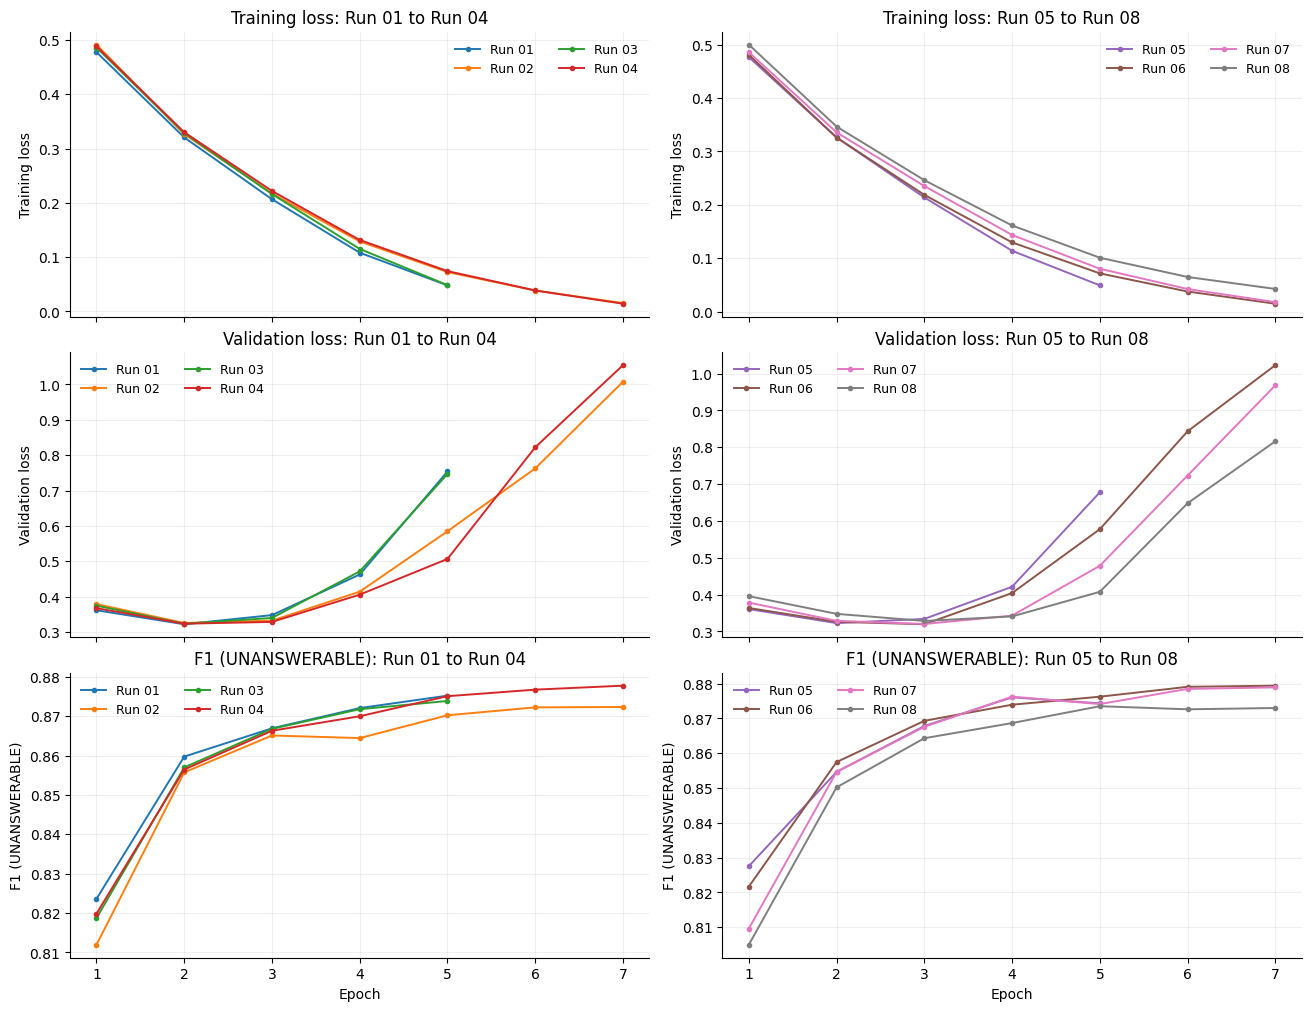

For Run 06, training loss changes from **0.4809** to **0.0150**. Validation loss reaches its minimum (**0.3193**) at epoch **3**, then ends at **1.0229**. The highest positive-class F1 occurs at epoch **7**. Falling training loss and increasing validation loss are consistent with overfitting in the loss criterion, while F1 can still improve. The curves do not identify a causal mechanism or justify replacing the predefined F1 selection criterion.

In [4]:
# Split runs into explicit cohorts to keep all trajectories readable.
names = list(runs)
cohorts = [names[:4], names[4:]]
fig, axes = plt.subplots(3, 2, figsize=(13, 10), sharex=True, layout='constrained')
settings = [('training', 'loss', 'Training loss'), ('validation', 'eval_loss', 'Validation loss'),
            ('validation', 'eval_f1', 'F1 (UNANSWERABLE)')]
for column, cohort in enumerate(cohorts):
    for row, (event_type, metric, ylabel) in enumerate(settings):
        ax = axes[row, column]
        for name in cohort:
            events = runs[name][event_type].sort_values('epoch')
            ax.plot(events['epoch'], events[metric], marker='o', markersize=3,
                    linewidth=1.4, color=colors[name], label=run_labels[name])
        ax.set(ylabel=ylabel, title=f"{ylabel}: {run_labels[cohort[0]]} to {run_labels[cohort[-1]]}")
        ax.grid(alpha=0.2)
        ax.legend(ncol=2, frameon=False, fontsize=9)
        ax.set_xticks(sorted({e for name in cohort for e in runs[name]['validation']['epoch']}))
        if row == 2:
            ax.set_xlabel('Epoch')
plt.show()
selected = runs[selected_run]
train_events = selected['training'].sort_values('epoch')
val_events = selected['validation'].sort_values('epoch')
min_loss = val_events.loc[val_events['eval_loss'].idxmin()]
display(Markdown(
    f"For {run_labels[selected_run]}, training loss changes from "
    f"**{train_events.iloc[0]['loss']:.4f}** to **{train_events.iloc[-1]['loss']:.4f}**. "
    f"Validation loss reaches its minimum (**{min_loss['eval_loss']:.4f}**) at epoch "
    f"**{int(min_loss['epoch'])}**, then ends at **{val_events.iloc[-1]['eval_loss']:.4f}**. "
    f"The highest positive-class F1 occurs at epoch **{int(selected['best']['epoch'])}**. "
    "Falling training loss and increasing validation loss are consistent with overfitting "
    "in the loss criterion, while F1 can still improve. The curves do not identify a causal "
    "mechanism or justify replacing the predefined F1 selection criterion."))

### Higher learning rate and longer scheduler horizon

The follow-up experiments test `6e-5 / 7 epochs` (Run 07) and `5e-5 / 10 epochs` (Run 08). They are compared with the selected `5e-5 / 7 epochs` run using validation evidence only. The actual stopping epoch is read from the history; no curve is extended to an unobserved epoch.

In [5]:
reference = runs[selected_run]
comparison = pd.DataFrame([
    {'Run': run_labels[name], 'Learning rate': runs[name]['config']['learning_rate'],
     'Maximum epochs': runs[name]['config']['max_epochs'],
     'Completed epochs': int(runs[name]['training']['epoch'].max()),
     'Best epoch': int(runs[name]['best']['epoch']),
     'Best F1': runs[name]['checkpoint_f1'],
     'F1 difference from selected run (pp)': 100 * (runs[name]['checkpoint_f1'] - reference['checkpoint_f1'])}
    for name in [selected_run, 'run_07', 'run_08']]).set_index('Run')
display(comparison.style.format({'Learning rate': '{:.0e}', 'Best F1': '{:.6f}',
                                'F1 difference from selected run (pp)': '{:.4f}'}))
long_run = runs['run_08']
long_val = long_run['validation'].sort_values('epoch')
actual_epochs = int(long_val['epoch'].max())
no_improvement = int((long_val['epoch'] > long_run['best']['epoch']).sum())
display(Markdown(
    f"Run 07 tests **{runs['run_07']['config']['learning_rate']:.0e}** with a seven-epoch budget. "
    "It does not exceed the selected run's validation F1. Run 08 retains learning rate "
    f"**{long_run['config']['learning_rate']:.0e}** but plans **{long_run['config']['max_epochs']} epochs**. "
    f"It actually ends at epoch **{actual_epochs}**, with its best checkpoint at epoch "
    f"**{int(long_run['best']['epoch'])}** and **{no_improvement}** subsequent validations "
    "without a higher F1, consistent with early stopping patience 2. It does not reach epoch 10. "
    f"Its scheduler nevertheless uses the original **{long_run['config']['planned_optimizer_steps']:,}** "
    f"planned steps and **{long_run['config']['warmup_steps']}** warmup steps, versus "
    f"**{reference['config']['planned_optimizer_steps']:,}** and **{reference['config']['warmup_steps']}** "
    "for the selected seven-epoch run. The longer-budget run is initialized anew from pretrained "
    "weights; it is not a continuation, and its learning-rate trajectory already differs before stopping."))

,Learning rate,Maximum epochs,Completed epochs,Best epoch,Best F1,F1 difference from selected run (pp)
Run,,,,,,
Run 06,5e-05,7,7,7,0.879413,0.0000
Run 07,6e-05,7,7,7,0.878925,-0.0488
Run 08,5e-05,10,7,5,0.873512,-0.5901


Run 07 tests **6e-05** with a seven-epoch budget. It does not exceed the selected run's validation F1. Run 08 retains learning rate **5e-05** but plans **10 epochs**. It actually ends at epoch **7**, with its best checkpoint at epoch **5** and **2** subsequent validations without a higher F1, consistent with early stopping patience 2. It does not reach epoch 10. Its scheduler nevertheless uses the original **15,960** planned steps and **798** warmup steps, versus **11,172** and **559** for the selected seven-epoch run. The longer-budget run is initialized anew from pretrained weights; it is not a continuation, and its learning-rate trajectory already differs before stopping.

## 5. Model Selection

The selected checkpoint is fixed by the highest SUM validation F1 for UNANSWERABLE among the completed runs. Training loss and test performance do not replace this rule. The search covers a limited set of learning rates and budgets with one seed, without establishing a global optimum, statistical significance or exact experiment execution times.

In [6]:
checkpoint_name = Path(runs[selected_run]['report']['best_checkpoint']).name
display(Markdown(
    f"Selected: **{MODEL_NAME} {run_labels[selected_run]}**, checkpoint **{checkpoint_name}**, "
    f"epoch **{int(runs[selected_run]['best']['epoch'])}**, validation F1 "
    f"**{runs[selected_run]['checkpoint_f1']:.6f}**. The frozen evaluator "
    "`src/24_evaluate_encoders.py::resolve_selection` resolves the recorded checkpoint "
    "under the selected run, with a run-local best-model export fallback. The actual loaded "
    "path is preserved in each evaluation's metadata and displayed below. Neither SUM Test "
    "nor UMWP participates in the validation ranking above."))

Selected: **ModernBERT-base Run 06**, checkpoint **checkpoint-11172**, epoch **7**, validation F1 **0.879413**. The frozen evaluator `src/24_evaluate_encoders.py::resolve_selection` resolves the recorded checkpoint under the selected run, with a run-local best-model export fallback. The actual loaded path is preserved in each evaluation's metadata and displayed below. Neither SUM Test nor UMWP participates in the validation ranking above.

## 6. Test Evaluation

Load the frozen selected-run evaluations from `results/modernbert/run_06/sum_test/`, `results/modernbert/run_06/umwp/`, and `results/modernbert/run_06/mate/`. Metrics and confusion matrices are read from the saved files; available `classification_report.json` files provide additional consistency checks. Expected sizes are 10,944 SUM Test, 5,200 UMWP and 9,586 MATE examples.

`src/24_evaluate_encoders.py` uses the saved model/tokenizer, dynamic padding, truncation at 256, batch size 32, FP32, `model.eval()`, no gradients and deterministic inference. It does not tune thresholds or choose another checkpoint. The notebook verifies saved counts, labels, matrix/metric agreement and model-selection provenance; it does not run the evaluator or import its model-loading dependencies. Missing artifacts are explicitly reported.

,Examples,Accuracy,Precision (UNANSWERABLE),Recall (UNANSWERABLE),F1 (UNANSWERABLE),Macro F1
Dataset,,,,,,
SUM Test,10944,87.61%,90.32%,84.25%,87.18%,87.60%
UMWP,5200,69.69%,79.66%,52.88%,63.57%,68.81%
MATE,9586,73.51%,74.30%,71.90%,73.08%,73.51%


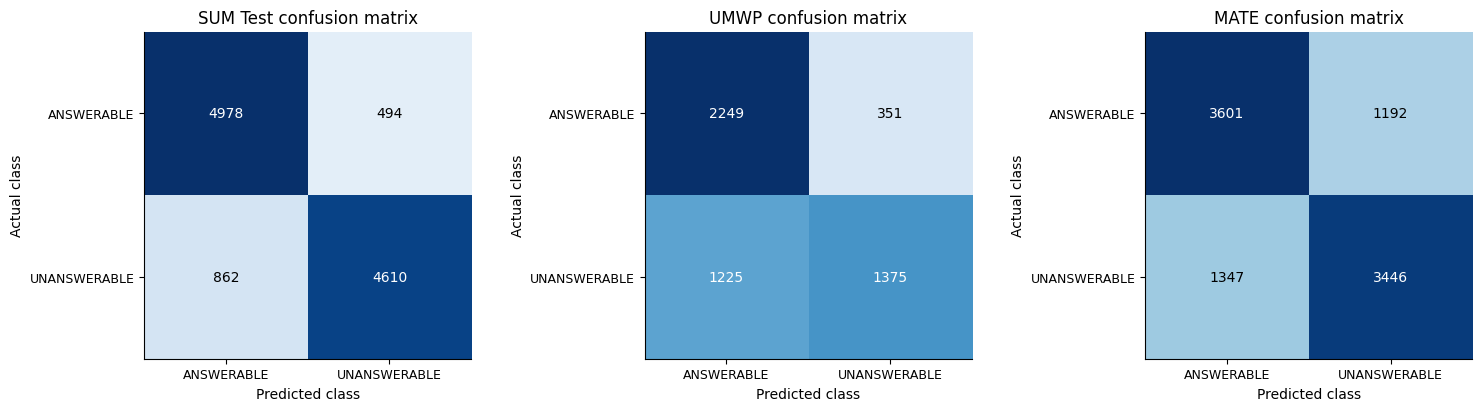

Matrices show absolute counts, with actual classes in rows and predicted classes in columns. Each dataset has its own color scale; because sample sizes differ, colors do not directly measure the performance gap.

,Loaded model path,Resolution,Parameter dtype,Attention backend,Dataset SHA-256
Dataset,,,,,
SUM Test,/home/arikanmurat@edu.local/projects/CDS1092_N...,validation_metadata_checkpoint,torch.float32,sdpa,c1e4bac1e1d1f27ab8a6408ac68ae710faf521822bff49...
UMWP,/home/arikanmurat@edu.local/projects/CDS1092_N...,validation_metadata_checkpoint,torch.float32,sdpa,92df3bed2d3cee139c6ddbca2673fca0a1687aa9f90b3c...
MATE,/home/arikanmurat@edu.local/projects/CDS1092_N...,validation_metadata_checkpoint,torch.float32,sdpa,377f7a28a6b2a5236ce24eeebc889c99ec38ff92c52c9b...


In [7]:
expected_examples = {"sum_test": 10944, "umwp": 5200, "mate": 9586}
evaluation = {}
confusion_matrices = {}
classification_reports = {}
missing_artifacts = []
for folder, dataset_name in [("sum_test", "SUM Test"), ("umwp", "UMWP"), ("mate", "MATE")]:
    directory = RESULTS_DIR / selected_run / folder
    required = [directory / 'metrics.json', directory / 'confusion_matrix.csv']
    missing = [str(p.relative_to(PROJECT_ROOT)) for p in required if not p.is_file()]
    if missing:
        missing_artifacts.extend(missing)
        continue
    m = read_json(directory / 'metrics.json')
    if m['selected_run'] != selected_run or m['positive_class'] != 'UNANSWERABLE':
        raise ValueError(f'{folder}: unexpected run or positive class')
    if m.get('model_family') != MODEL_FAMILY or m['confusion_matrix_label_order'] != LABELS:
        raise ValueError(f'{folder}: unexpected model or class order')
    if m['total_examples'] != expected_examples[folder]:
        raise ValueError(f'{folder}: unexpected number of examples')
    if m.get('label_to_id') != {'ANSWERABLE': 0, 'UNANSWERABLE': 1}:
        raise ValueError(f'{folder}: unexpected label mapping')
    if m['prediction_rule'] != 'argmax' or m['eval_batch_size'] != 32:
        raise ValueError(f'{folder}: unexpected inference settings')
    if not math.isclose(m['best_checkpoint_validation_f1'], runs[selected_run]['checkpoint_f1'], abs_tol=1e-12):
        raise ValueError(f'{folder}: validation checkpoint provenance differs')
    if m['max_length'] != runs[selected_run]['config']['max_length']:
        raise ValueError(f'{folder}: maximum sequence length differs')
    matrix = pd.read_csv(directory / 'confusion_matrix.csv', index_col=0)
    if (matrix.sum(axis=1) != expected_examples[folder] // 2).any() or list(matrix.index) != LABELS or list(matrix.columns) != LABELS:
        raise ValueError(f'{folder}: unexpected confusion-matrix labels')
    if matrix.values.tolist() != m['confusion_matrix'] or int(matrix.values.sum()) != m['total_examples']:
        raise ValueError(f'{folder}: CSV/JSON matrix or total count disagrees')
    tn, fp = matrix.iloc[0].tolist()
    fn, tp = matrix.iloc[1].tolist()
    reconstructed = {'accuracy': (tn + tp) / m['total_examples'],
                     'precision_unanswerable': tp / (tp + fp) if tp + fp else 0,
                     'recall_unanswerable': tp / (tp + fn) if tp + fn else 0,
                     'f1_unanswerable': 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0}
    for key, value in reconstructed.items():
        if not math.isclose(value, m[key], abs_tol=1e-12):
            raise ValueError(f'{folder}: matrix/metric inconsistency for {key}')
    report_path = directory / 'classification_report.json'
    if report_path.is_file():
        report = read_json(report_path)
        for report_key, metric_key in [('precision', 'precision_unanswerable'), ('recall', 'recall_unanswerable'), ('f1-score', 'f1_unanswerable')]:
            if not math.isclose(report['UNANSWERABLE'][report_key], m[metric_key], abs_tol=1e-12):
                raise ValueError(f'{folder}: classification report disagrees with metrics.json')
        classification_reports[dataset_name] = report
    else:
        print(f'Additional classification report missing: {report_path.relative_to(PROJECT_ROOT)}')
    evaluation[dataset_name] = m
    confusion_matrices[dataset_name] = matrix
if missing_artifacts:
    raise FileNotFoundError('Missing evaluation artifacts: ' + ', '.join(missing_artifacts))
if evaluation:
    test_table = pd.DataFrame([{'Dataset': name, 'Examples': m['total_examples'], 'Accuracy': m['accuracy'], 'Precision (UNANSWERABLE)': m['precision_unanswerable'], 'Recall (UNANSWERABLE)': m['recall_unanswerable'], 'F1 (UNANSWERABLE)': m['f1_unanswerable'], 'Macro F1': m['macro_f1']} for name, m in evaluation.items()]).set_index('Dataset')
    display(test_table.style.format({c: '{:.2%}' for c in test_table.columns if c != 'Examples'}))
    fig, axes = plt.subplots(1, len(evaluation), figsize=(5 * len(evaluation), 4), layout='constrained', squeeze=False)
    for ax, (name, matrix) in zip(axes[0], confusion_matrices.items()):
        ax.imshow(matrix.values, cmap='Blues', vmin=0, vmax=matrix.values.max())
        for row in range(2):
            for col in range(2):
                count = int(matrix.iloc[row, col])
                ax.text(col, row, str(count), ha='center', va='center', color='white' if count > matrix.values.max() / 2 else 'black')
        ax.set_xticks([0, 1], LABELS, fontsize=9)
        ax.set_yticks([0, 1], LABELS, fontsize=9)
        ax.set(title=f'{name} confusion matrix', xlabel='Predicted class', ylabel='Actual class')
    plt.show()
    display(Markdown('Matrices show absolute counts, with actual classes in rows and predicted classes in columns. Each dataset has its own color scale; because sample sizes differ, colors do not directly measure the performance gap.'))
if evaluation:
    display(pd.DataFrame([
        {'Dataset': name, 'Loaded model path': m['model_path'],
         'Resolution': m['model_resolution'], 'Parameter dtype': m['model_parameter_dtype'],
         'Attention backend': m['attention_implementation'], 'Dataset SHA-256': m['dataset_sha256']}
        for name, m in evaluation.items()]).set_index('Dataset'))

In [8]:
sum_f1 = evaluation["SUM Test"]["f1_unanswerable"]
observations = []
for name in ("UMWP", "MATE"):
    metrics = evaluation[name]
    matrix = confusion_matrices[name]
    gap = 100 * (metrics["f1_unanswerable"] - sum_f1)
    observations.append(
        f"- **{name}**: {gap:+.2f} percentage points in UNANSWERABLE F1 versus SUM Test. "
        f"Precision was {metrics['precision_unanswerable']:.2%} and recall was "
        f"{metrics['recall_unanswerable']:.2%}. There were "
        f"{matrix.loc['ANSWERABLE', 'UNANSWERABLE']:,} false positives and "
        f"{matrix.loc['UNANSWERABLE', 'ANSWERABLE']:,} false negatives."
    )
external_gap = 100 * (evaluation["MATE"]["f1_unanswerable"] - evaluation["UMWP"]["f1_unanswerable"])
observations.append(f"- MATE versus UMWP: {external_gap:+.2f} percentage points in UNANSWERABLE F1.")
display(Markdown("\n".join(observations)))

if 'UMWP' in evaluation and 'duplicate_consistency' in evaluation['UMWP']:
    d = evaluation['UMWP']['duplicate_consistency']
    display(Markdown(f"UMWP contains **{d['duplicated_question_texts']}** repeated question texts, including **{d['conflicting_ground_truth_texts']}** with conflicting labels. In **{d['texts_with_inconsistent_predictions']}** groups, predictions differ for identical texts. All official rows are retained; label conflicts limit interpretation of individual errors."))

- **UMWP**: -23.61 percentage points in UNANSWERABLE F1 versus SUM Test. Precision was 79.66% and recall was 52.88%. There were 351 false positives and 1,225 false negatives.
- **MATE**: -14.10 percentage points in UNANSWERABLE F1 versus SUM Test. Precision was 74.30% and recall was 71.90%. There were 1,192 false positives and 1,347 false negatives.
- MATE versus UMWP: +9.51 percentage points in UNANSWERABLE F1.

UMWP contains **10** repeated question texts, including **5** with conflicting labels. In **0** groups, predictions differ for identical texts. All official rows are retained; label conflicts limit interpretation of individual errors.

### Limitations of Interpretation

The experiments use one seed and a limited sequential hyperparameter search. Small validation margins do not establish statistical significance. Loss and F1 can prefer different epochs; the trajectories alone do not diagnose why their trends differ. Fixed 256-token truncation may remove information, but no truncation-specific error study is available.

Exact pair/text isolation of SUM splits does not rule out semantic similarity or pretraining overlap. UMWP's preserved conflicting labels limit interpretation of some individual errors. The immutable pretrained revision is unavailable in the saved metadata, although software versions, checkpoint provenance and evaluation dataset fingerprints are recorded. These notebooks require only result artifacts and do not verify local checkpoint weights. The saved results establish performance under this protocol, rather than a causal explanation of the external transfer gap.

## 7. Conclusion

In [9]:
scores = "; ".join(
    f"{name} {metrics['f1_unanswerable']:.2%}" for name, metrics in evaluation.items()
)
display(Markdown(
    f"The frozen {selected_run} checkpoint, selected by SUM validation F1 "
    f"({runs[selected_run]['checkpoint_f1']:.2%}), achieved UNANSWERABLE F1 of **{scores}**. "
    "The external results describe transfer under the saved protocol. They do not establish "
    "what caused the difference between the two external benchmarks."
))

The frozen run_06 checkpoint, selected by SUM validation F1 (87.94%), achieved UNANSWERABLE F1 of **SUM Test 87.18%; UMWP 63.57%; MATE 73.08%**. The external results describe transfer under the saved protocol. They do not establish what caused the difference between the two external benchmarks.